In [1]:
from pathlib import Path  # clean file paths

import matplotlib.pyplot as plt  # charts
import pandas as pd  # tables

ROOT = Path("..")  # the notebook runs inside notebooks/, so the project root is one level up
DATA = ROOT / "data" / "processed"  # where features.parquet lives
FIG_DIR = ROOT / "reports" / "figures"  # same chart folder as Day 6
plt.style.use("seaborn-v0_8-whitegrid")  # same style as the EDA notebook

df = pd.read_parquet(DATA / "features.parquet")  # the model-ready table
df = df[df["fire_tomorrow"].notna()]  # drop each cell's last day (no label)
print(df.shape, f"positive rate {df['fire_tomorrow'].mean():.4%}")  # size and imbalance

(2630808, 51) positive rate 0.2020%


In [2]:
missing = df.isna().mean()  # share of missing values per column
print(missing[missing > 0].sort_values(ascending=False).round(3))  # only columns with gaps, biggest first

no_ndvi = df[df["ndvi"].isna()].groupby("cell_id").size().sort_values(ascending=False)  # missing NDVI days per cell
print("\nCells with missing NDVI (days):")  # header
print(no_ndvi.head(10))  # the worst cells; ~5,390 days means "never has NDVI"

tmax               0.744
rh_min             0.744
precip             0.744
wind_max           0.744
gust_max           0.744
et0                0.744
vpd_max            0.744
dry_streak         0.744
tmax_mean_3d       0.744
rh_min_mean_3d     0.744
wind_max_3d        0.744
vpd_max_mean_3d    0.744
rh_min_mean_7d     0.743
vpd_max_mean_7d    0.743
wind_max_7d        0.743
tmax_mean_7d       0.743
precip_sum_7d      0.743
precip_sum_30d     0.739
et0_sum_30d        0.739
precip_sum_90d     0.728
ndvi_anomaly       0.021
ndvi_change_30d    0.012
ndvi_age_days      0.006
ndvi               0.006
dtype: float64

Cells with missing NDVI (days):
cell_id
2      5391
40     5391
398    5391
dtype: int64


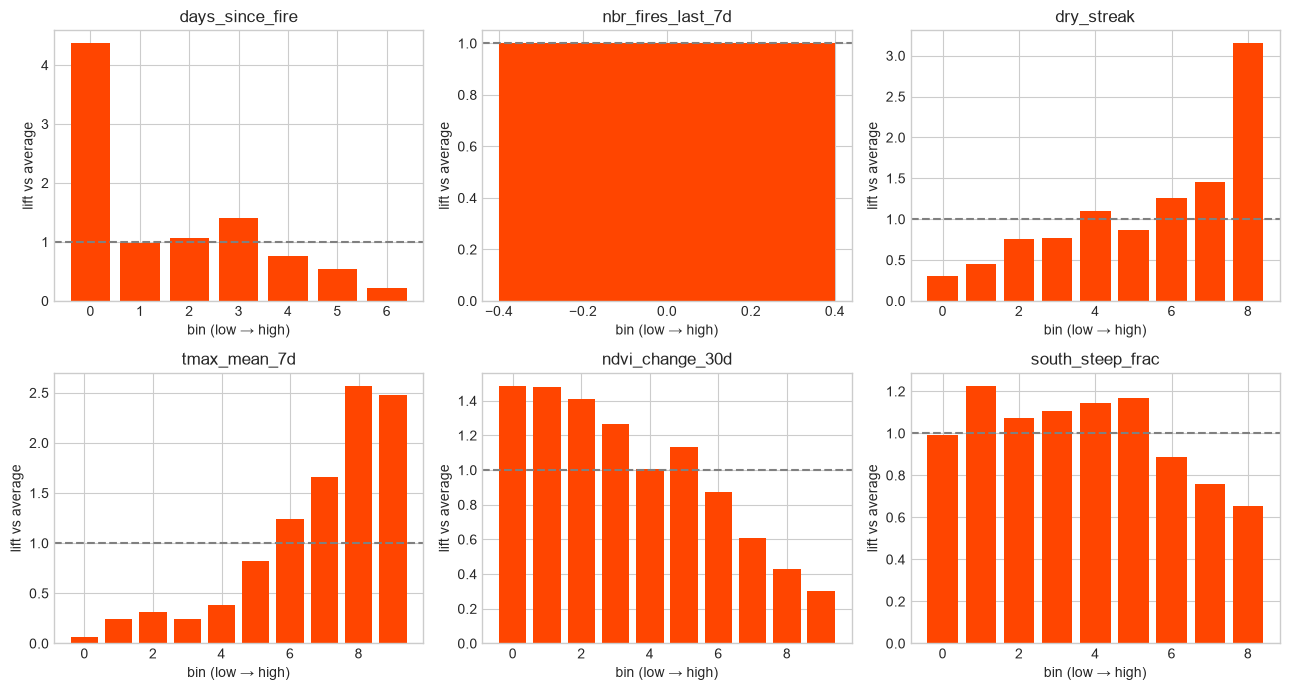

In [3]:
feats = ["days_since_fire", "nbr_fires_last_7d", "dry_streak", "tmax_mean_7d", "ndvi_change_30d", "south_steep_frac"]  # one feature per group
fig, axes = plt.subplots(2, 3, figsize=(13, 7))  # 6 small charts in 2 rows
for ax, f in zip(axes.ravel(), feats):  # one chart per feature
    sub = df[[f, "fire_tomorrow"]].dropna()  # rows where this feature exists (weather = 2012–2015 for now)
    bins = pd.qcut(sub[f], 10, duplicates="drop")  # 10 equal-size bins from low to high (fewer if many values repeat)
    rate = sub.groupby(bins, observed=True)["fire_tomorrow"].mean()  # fire rate in each bin
    lift = rate / sub["fire_tomorrow"].mean()  # compare each bin with the average of the same rows
    ax.bar(range(len(lift)), lift.values, color="orangered")  # one bar per bin
    ax.axhline(1, color="gray", linestyle="--")  # the "average risk" line
    ax.set_title(f)  # feature name
    ax.set_xlabel("bin (low → high)")  # x-axis meaning
    ax.set_ylabel("lift vs average")  # y-axis meaning
plt.tight_layout()  # stop labels from overlapping
plt.savefig(FIG_DIR / "07_feature_lift.png", dpi=150, bbox_inches="tight")  # save for the README
plt.show()  # display

In [4]:
nb = df[["nbr_fires_last_7d", "fire_tomorrow"]]  # the neighbor feature and the label
groups = pd.cut(nb["nbr_fires_last_7d"], bins=[-0.5, 0.5, 1.5, 3.5, float("inf")], labels=["0", "1", "2-3", "4+"])  # hand-made groups instead of equal-size bins
summary = pd.DataFrame({  # one row per group
    "share_of_rows": groups.value_counts(normalize=True).sort_index(),  # how common each group is
    "lift": nb.groupby(groups, observed=True)["fire_tomorrow"].mean() / nb["fire_tomorrow"].mean(),  # fire rate vs the average
})  # end of the table
print(summary.round(3))  # show it

                   share_of_rows    lift
nbr_fires_last_7d                       
0                          0.922   0.737
1                          0.062   3.190
2-3                        0.015   5.982
4+                         0.002  19.919
